# Practical Machine Learning — Day 01 Lab
## Data Preparation, Cleaning and Transformation Using Python
**CDAC PGCP-AI · Practical Machine Learning · 23 October 2026 · Duration: 3 hours**

> 🔒 **TRAINER SOLUTION NOTEBOOK — do not distribute to students.**
> Same exercise IDs, same cell order and same dataset as the student notebook. Every blank is filled, every cell was executed from a fresh kernel, and all printed numbers are computed from the data (nothing is hard-coded).

## Section 0 — Welcome and Instructions

### 🎯 Learning objectives
By the end of this lab you will be able to:
1. Load and explore a raw dataset and understand its data types.
2. Find missing values, duplicates and inconsistent values.
3. Clean numerical and categorical columns using documented business rules.
4. Perform basic transformations (encoding, normalisation, standardisation).
5. Validate your results and export a cleaned dataset.

### ⏱️ Estimated time (180 minutes)
| Stage | Exercises | Time |
|---|---|---|
| A — Explore the dataset | A1 – A9 | 60 min |
| B — Clean the dataset | B1 – B9 | 60 min |
| C — Transform and validate | C1 – C8 | 60 min |

### 📁 Files you need (keep them in the same folder as this notebook)
- `06_customer_data_dirty.csv` — the raw dataset (**never edit or overwrite it**)
- `07_Data_Dictionary.xlsx` — column meanings and the **business rules** you must apply

### ✍️ How to complete the blank code
- A blank looks like `____`. Replace it with the missing method, value or expression.
- Every blank is labelled `# TODO (ID)` — e.g. `A1-1` is the first blank of Exercise A1.
- Until a blank is completed, the cell will **fail on purpose** (usually with `AttributeError`, `NameError` or `SyntaxError`). That is normal.
- Some tasks are *debugging* tasks (find and fix the bug) or *write-it-yourself* tasks — they are marked **Level 4** and **Level 5**.

| Level | What you do |
|---|---|
| 1 | Complete a pandas method |
| 2 | Complete a statement, argument or expression |
| 3 | Choose the correct preprocessing technique |
| 4 | Debug a short, incorrect snippet |
| 5 | Write a small validation check on your own |

### ▶️ How to run cells
Click a cell and press **Shift + Enter**. **Run the cells in order, top to bottom.** If something behaves strangely, use *Kernel → Restart & Run All* (Colab: *Runtime → Restart and run all*) after finishing your blanks.

### 📤 What to submit
1. This completed notebook (`.ipynb`)
2. `customer_data_cleaned.csv` (created in Exercise C7)
3. The before-and-after quality summary table (created in Exercise C6)
4. Your short written conclusions (Section 17)

### ⚠️ Golden rules
- Work on a **copy** of the data (`clean_df`), never on the raw `df`.
- **Do not delete rows just because they look odd.** Decide *why* first; flag what you cannot resolve.
- Every cleaning decision must be explainable: *what was wrong, what did I do, why?*
- No machine-learning model is trained today. Day 01 is about getting the data ready.

---
# STAGE A — Explore the Dataset (60 min)
## Section 1 — Import Libraries and Load Data

### Exercise A1 — Load the CSV

**Level 1** &nbsp;|&nbsp; **Task:** Read `06_customer_data_dirty.csv` into a DataFrame called `df`.

**You should see:** A message *Loaded: 06_customer_data_dirty.csv* (no error).

<details><summary>💡 Hint (try first without it)</summary>

Pandas has a family of `read_...` functions, one per file type. Which one reads comma-separated values?

</details>

In [35]:
# ===== Exercise A1 =====
import os, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

# Optional (Google Colab only): upload the CSV. Outside Colab this just prints a message.
# try:
#     from google.colab import files
#     if not os.path.exists("06_customer_data_dirty.csv"):
#         files.upload()
# except ImportError:
#     pass

DATA_FILE = "06_customer_data_dirty.csv"
# assert os.path.exists(DATA_FILE), f"{DATA_FILE} not found in {os.getcwd()} - place it next to this notebook"

# # Fingerprint of the raw file: at the end we prove we never modified it
# RAW_FINGERPRINT = hashlib.md5(open(DATA_FILE, "rb").read()).hexdigest()

# # TODO (A1-1): complete the pandas function that reads a CSV file
df = pd.read_csv(DATA_FILE)
print("Loaded:", DATA_FILE)

Loaded: 06_customer_data_dirty.csv


**Trainer note (A1):** `pd.read_csv` is the standard reader. The file is UTF-8 (with a byte-order mark so Excel shows `₹` correctly); pandas handles the BOM automatically. The MD5 fingerprint is a simple, beginner-friendly way to *prove* the raw file is untouched.

### Exercise A2 — Display the first 10 records

**Level 1** &nbsp;|&nbsp; **Task:** Show the first **10** rows of `df`.

**You should see:** A table with 10 rows and 9 columns. Look closely — can you already spot anything odd?

<details><summary>💡 Hint (try first without it)</summary>

The method name is the 'top of the table' word. It takes the number of rows as an argument.

</details>

In [36]:
# ===== Exercise A2 =====
# TODO (A2-1): show the first 10 records
df.head(10)

,customer_id,age,annual_income_inr,city,account_type,preferred_channel,signup_date,transactions_last_30d,avg_transaction_amount_inr
0,CUST0001,32,768000,Mumbai,Savings,Mobile,2024-08-21,9.0,6664.30
1,CUST0002,40,INR 770000,Mumbai,Current,Mobile,2019-06-24,21.0,2508.71
2,CUST0003,21,NaN,Bengaluru,Basic,Mobile,2018-08-27,16.0,7929.87
3,CUST0004,999,585500,Ahmedabad,Savings,Web,2022-12-14,16.0,3039.58
4,CUST0005,54,570000,Delhi,Premium,branch,2022-02-03,20.0,5056.26
5,CUST0006,34,306500,Delhi,Savings,Mobile,2020-02-18,14.0,4975.35
6,CUST0007,32 yrs,862000,Mumbai,Savings,Branch,17/02/2024,13.0,1332.89
7,CUST0008,58,591500,Delhi,Premium,Mobile,2019-02-12,19.0,1369.91
8,CUST0009,33,3258000,New Delhi,Premium,Web,2023-08-10,18.0,3732.06
9,CUST0010,43,833500,Mumbai,Savings,Mobile,2025-07-19,12.0,949.32


**Trainer note (A2):** `df.head(10)`. `df.sample(10, random_state=1)` is a good alternative because the first rows are rarely representative. Ask students: *what odd values can you see already?* (padded city, `INR` prefix, blank cells, a very large age.)

## Section 2 — Explore the Dataset

### Exercise A3 — Rows and columns

**Level 1** &nbsp;|&nbsp; **Task:** Find how many rows and columns `df` has.

**You should see:** `Rows: <number>` and `Columns: 9`, followed by the list of column names.

<details><summary>💡 Hint (try first without it)</summary>

It is an *attribute* (no brackets) that returns a pair: (number of rows, number of columns).

</details>

In [37]:
# ===== Exercise A3 =====
# TODO (A3-1): complete the attribute that returns (rows, columns)
rows, columns = df.shape

print("Rows:", rows)
print("Columns:", columns)
print("Column names:", list(df.columns))

Rows: 460
Columns: 9
Column names: ['customer_id', 'age', 'annual_income_inr', 'city', 'account_type', 'preferred_channel', 'signup_date', 'transactions_last_30d', 'avg_transaction_amount_inr']


**Trainer note (A3):** `shape` is an attribute, not a method — a classic beginner slip is `df.shape()` (TypeError: tuple is not callable). `len(df)` gives rows only.

### Exercise A4 — Understand the data types

**Level 1** &nbsp;|&nbsp; **Task:** Display the data type and the number of non-null values of every column.

**You should see:** A summary listing 9 columns. **Look at the Dtype column:** which columns that *should* be numbers are not?

<details><summary>💡 Hint (try first without it)</summary>

The method name is a synonym for 'information'.

</details>

**🤔 Reflect (A4):** Which numeric-looking columns are stored as text, and what do you think causes this?

In [4]:
# ===== Exercise A4 =====
# TODO (A4-1): display column dtypes, non-null counts and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 460 entries, 0 to 459
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_id                 460 non-null    str    
 1   age                         438 non-null    str    
 2   annual_income_inr           429 non-null    str    
 3   city                        444 non-null    str    
 4   account_type                450 non-null    str    
 5   preferred_channel           442 non-null    str    
 6   signup_date                 448 non-null    str    
 7   transactions_last_30d       439 non-null    float64
 8   avg_transaction_amount_inr  435 non-null    float64
dtypes: float64(2), str(7)
memory usage: 32.5 KB


**Trainer note (A4):** `age` and `annual_income_inr` are text (`object`, or `str` in pandas 3) because a few cells contain `yrs`, `₹`, `INR` or commas — one bad cell turns the whole column into text. `transactions_last_30d` and `avg_transaction_amount_inr` are floats (not ints) because they contain missing values (NaN). `signup_date` is text, not a date.

### Exercise A5 — Descriptive statistics

**Level 1** &nbsp;|&nbsp; **Task:** Run the summary-statistics cells and interpret them.

**You should see:** A table of count / mean / min / max for numeric columns, then one for text columns. **Notice which columns are missing from the first table.**

<details><summary>💡 Hint (try first without it)</summary>

No blank here — just run the cells. Compare *min* and *max* with what you would expect from real customers.

</details>

**🤔 Reflect (A5):** Why do only two columns appear in `df.describe()`? What would a numeric summary of `annual_income_inr` tell us if it were converted?

In [5]:
# ===== Exercise A5 =====
# Numeric summary (only columns pandas already treats as numbers)
display(df.describe())

# Summary of ALL columns, transposed so it is easier to read
display(df.describe(include="all").T)

,transactions_last_30d,avg_transaction_amount_inr
count,439.000000,4.350000e+02
mean,19.897494,1.287812e+04
std,53.994681,8.863527e+04
min,-12.000000,-9.999000e+03
25%,11.000000,2.116905e+03
50%,15.000000,3.338330e+03
75%,20.000000,5.213915e+03
max,999.000000,1.250000e+06


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,460,440,CUST0035,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,438,63,21,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income_inr,429,398,432000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,444,40,Mumbai,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
account_type,450,17,Savings,227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preferred_channel,442,15,Mobile,206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
signup_date,448,408,2018-08-27,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transactions_last_30d,439.0,NaN,NaN,NaN,19.897494,53.994681,-12.0,11.0,15.0,20.0,999.0
avg_transaction_amount_inr,435.0,NaN,NaN,NaN,12878.124138,88635.27145,-9999.0,2116.905,3338.33,5213.915,1250000.0


**Trainer note (A5):** Only `transactions_last_30d` and `avg_transaction_amount_inr` appear because the other numeric-looking columns are stored as text. The `min`/`max` rows already expose negative counts and absurdly large amounts — a good moment to link back to the theory on *EDA before changing anything*.

## Section 3 — Missing Values

### Exercise A6 — Count missing values

**Level 1** &nbsp;|&nbsp; **Task:** Count the missing values in every column and express them as a percentage of all rows.

**You should see:** A table with one row per column: `missing_count` and `missing_percent`, sorted from most to least missing.

<details><summary>💡 Hint (try first without it)</summary>

Pandas has two equivalent methods that return True where a value is missing (one sounds like 'is null', the other like 'is NA'). `True` counts as 1 when you `.sum()`.

</details>

**🤔 Reflect (A6):** Which column has the highest number of missing values? Is the amount large enough to worry about?

In [5]:
# ===== Exercise A6 =====
# TODO (A6-1): True where a value is missing, then add them up per column
missing_values = df.isnull().sum()

missing_pct = (missing_values / len(df) * 100).round(2)
missing_report = pd.DataFrame({"missing_count": missing_values, "missing_percent": missing_pct})
missing_report.sort_values("missing_count", ascending=False)

,missing_count,missing_percent
annual_income_inr,31,6.74
avg_transaction_amount_inr,25,5.43
age,22,4.78
transactions_last_30d,21,4.57
preferred_channel,18,3.91
city,16,3.48
signup_date,12,2.61
account_type,10,2.17
customer_id,0,0.00


**Trainer note (A6):** `isna()` and `isnull()` are identical — accept either. Remind students that only *truly empty cells* are counted here; text such as `Unknown` or a padded value is not "missing" to pandas.

In [6]:
# Model answer (computed, not hard-coded)
worst = missing_report["missing_count"].idxmax()
print(f"Highest number of missing values: {worst} -> {missing_report.loc[worst, 'missing_count']} rows ({missing_report.loc[worst, 'missing_percent']}%)")
print("Every column with missing data is below 10%: ", bool((missing_report['missing_percent'] < 10).all()))

Highest number of missing values: annual_income_inr -> 31 rows (6.74%)
Every column with missing data is below 10%:  True


## Section 4 — Duplicate Records

### Exercise A7 — Exact duplicates and repeated customer IDs

**Level 2** &nbsp;|&nbsp; **Task:** (a) Count rows that are **exact copies** of an earlier row. (b) Find rows whose `customer_id` appears more than once, then separate *exact copies* from *conflicting* records.

**You should see:** Two counts, then a table of repeated-ID rows. Some IDs repeat with identical values; a few repeat with **different** values.

<details><summary>💡 Hint (try first without it)</summary>

(a) The method name is a synonym for 'repeated'. (b) `value_counts()` returns how many times each ID appears — which count means the ID is repeated?

</details>

**🤔 Reflect (A7):** Why would it be dangerous to remove every row whose customer_id repeats?

In [38]:
# ===== Exercise A7 =====
# (a) TODO (A7-1): count rows that are exact copies of an earlier row
exact_duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", exact_duplicate_count)

# (b) Repeated customer IDs: how many times does each ID appear?
id_counts = df["customer_id"].value_counts()
# TODO (A7-2): keep only the IDs that appear MORE than this many times (what count means "repeated"?)
repeated_ids = id_counts[id_counts > 1].index
repeated_id_rows = df.set_index("customer_id").loc[repeated_ids].reset_index().sort_values("customer_id")
print("Rows whose customer_id appears more than once:", len(repeated_id_rows))

# Which repeated IDs are exact copies, and which have CONFLICTING values? (provided)
# For every ID count the distinct values in each column; if ANY column has 2+ distinct values the rows disagree.
distinct_per_id = df.groupby("customer_id").nunique(dropna=False)
conflicting_ids = sorted(distinct_per_id[(distinct_per_id > 1).any(axis=1)].index)
exact_copy_ids = set(repeated_id_rows["customer_id"]) - set(conflicting_ids)
print("IDs repeated as exact copies :", len(exact_copy_ids))
print("IDs repeated with CONFLICTING data:", len(conflicting_ids))
df.set_index("customer_id").loc[conflicting_ids].head(10)

Exact duplicate rows: 12
Rows whose customer_id appears more than once: 40
IDs repeated as exact copies : 12
IDs repeated with CONFLICTING data: 8


,age,annual_income_inr,city,account_type,preferred_channel,signup_date,transactions_last_30d,avg_transaction_amount_inr
customer_id,,,,,,,,
CUST0043,40,1148500,Bengaluru,Savings,Mobile,2025-01-29,13.0,2006.84
CUST0043,40,1435500,Bengaluru,Savings,Mobile,2025-01-29,18.0,3210.94
CUST0074,51,2787000,Ahmedabad,Savings,Web,2025-04-30,14.0,5062.54
CUST0074,51,3484000,Ahmedabad,Savings,Web,2025-04-30,23.0,8100.06
CUST0167,34,3234000,Mumbai,Savings,Mobile,2018-07-02,27.0,3335.17
CUST0167,34,2310000,Mumbai,Savings,Mobile,2018-07-02,18.0,4168.96
CUST0205,51,1534000,Ahmedabad,Premium,Web,2019-05-02,20.0,1484.33
CUST0205,51,1074000,Ahmedabad,Savings,Web,2019-05-02,29.0,1929.63
CUST0252,39,831500,Mumbai,Current,Web,2020-01-20,18.0,5684.90


**Trainer note (A7):** Two very different problems share the word *duplicate*. **Exact duplicates** (identical in every column) are safe to drop. **Repeated IDs with different values** are *conflicts*: we cannot know which row is right without the source system, so Day 01 **flags** them and keeps both. `duplicated()` defaults to `keep='first'` (it hides the first row of every pair); `df['customer_id'].duplicated(keep=False)` is the one-line alternative for part (b) and is what students use in B7.

## Section 5 — Suspicious Values, Inconsistent Categories and Visual Checks

### Exercise A8 — Spot suspicious values and inconsistent categories

**Level 2** &nbsp;|&nbsp; **Task:** Run the inspection cells and **write down every problem you can find** (use the Issue Log below).

**You should see:** Value counts showing spelling variants, blanks and unexpected categories; and numeric checks showing ages outside 18–100 and negative values.

<details><summary>💡 Hint (try first without it)</summary>

Compare what you see with the rules in `07_Data_Dictionary.xlsx` (sheet *Business Rules*). A value is **invalid** if it breaks a hard rule, **suspicious** if it is possible but unusual.

</details>

**🤔 Reflect (A8):** When should a suspicious value be flagged instead of automatically replaced?

In [8]:
# ===== Exercise A8 =====
# (a) Inconsistent categories
for col in ["city", "account_type", "preferred_channel"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- city ---
city
Mumbai          67
Delhi           64
Bengaluru       51
Pune            43
Chennai         33
Kolkata         27
Ahmedabad       25
Hyderabad       24
Jaipur          19
NaN             16
Lucknow         13
Bangalore        8
Bombay           8
New Delhi        5
HYDERABAD        4
Madras           4
PUNE             4
 Mumbai          4
mumbai           3
AHMEDABAD        3
delhi            3
Calcutta         3
kolkata          2
Delhi            2
hyderabad        2
Delhi            2
Hyderabad        2
 Pune            2
Jaipur           2
LUCKNOW          2
Chennai          2
ahmedabad        2
Hyderabad        1
lucknow          1
 Hyderabad       1
pune             1
Pune             1
Ahmedabad        1
 Jaipur          1
Mumbai           1
JAIPUR           1
Name: count, dtype: int64

--- account_type ---
account_type
Savings     227
Current     102
Premium      70
NaN          10
SAVINGS       6
Savings       6
Gold          5
savings       5
 Savings      

In [9]:
# (b) Suspicious numbers. We convert a COPY just for inspection; df itself stays raw.
age_check = df["age"].astype(str).str.extract(r"(-?\d+)", expand=False).astype(float)   # grab the digits (keep a minus sign)
print("Ages written with letters (e.g. '34 yrs'):", df["age"].str.contains("[A-Za-z]", na=False).sum())
print(age_check.describe().round(1))
print("\nAges outside the valid range 18-100:")
display(df.loc[(age_check < 18) | (age_check > 100), ["customer_id", "age"]])

symbols_in_income = df["annual_income_inr"].str.contains(r"[^0-9\-]", na=False)
print("Income cells containing symbols, commas or letters:", symbols_in_income.sum())
display(df.loc[symbols_in_income, "annual_income_inr"].head(8))

print("Negative transaction counts :", (df["transactions_last_30d"] < 0).sum())
print("Negative average amounts    :", (df["avg_transaction_amount_inr"] < 0).sum())

Ages written with letters (e.g. '34 yrs'): 6
count    438.0
mean      40.7
std       48.9
min       -5.0
25%       30.0
50%       37.0
75%       44.0
max      999.0
Name: age, dtype: float64

Ages outside the valid range 18-100:


,customer_id,age
3,CUST0004,999
23,CUST0024,17
103,CUST0101,7
145,CUST0141,16
170,CUST0165,150
191,CUST0185,0
197,CUST0190,250
253,CUST0244,12
378,CUST0365,-5


Income cells containing symbols, commas or letters: 63


1     INR 770000
21     1,244,000
30     19,16,000
49      ₹1256500
51    ₹24,43,000
67      9,55,000
73     ₹7,00,500
74      7,38,500
Name: annual_income_inr, dtype: object

Negative transaction counts : 6
Negative average amounts    : 6


**Trainer note (A8) — model Issue Log (problem types; exact counts are printed by the cells above and listed in the Trainer Key):**
| Column | Problem type | Example | Rule |
|---|---|---|---|
| city | capitalisation / spaces / aliases (Bombay, Bangalore…) / blanks | `MUMBAI`, ` Pune `, `Bombay` | consistent standard city names |
| account_type | case/spaces, unexpected categories | `GOLD`, `Student` | Savings / Current / Premium |
| preferred_channel | case/spaces, unexpected categories | `ATM`, `Kiosk` | Mobile / Branch / Web |
| age | text (`34 yrs`), impossible (<18, >100), suspicious 90–100 | `250`, `-5` | 18–100 |
| annual_income_inr | `₹`, `INR`, commas; zero/negative; > ₹1 crore | `₹5,40,000`, `-450000` | > 0 |
| signup_date | three formats, invalid and future dates | `31/04/2024`, `2027-03-15` | valid date ≤ extract date |
| customer_id | padded / lower-case | ` CUST0007`, `cust0012` | `CUST` + 4 digits |

### Exercise A9 — Two exploratory visualisations

**Level 1** &nbsp;|&nbsp; **Task:** Create (1) a histogram of the raw ages and (2) a bar chart of the raw city values.

**You should see:** Two charts side by side. The histogram is stretched by impossible ages; the bar chart shows the same city split into many labels.

<details><summary>💡 Hint (try first without it)</summary>

A histogram method is named after the chart type. It needs the values and `bins=`.

</details>

**🤔 Reflect (A9):** What do the two charts reveal that `describe()` did not make obvious?

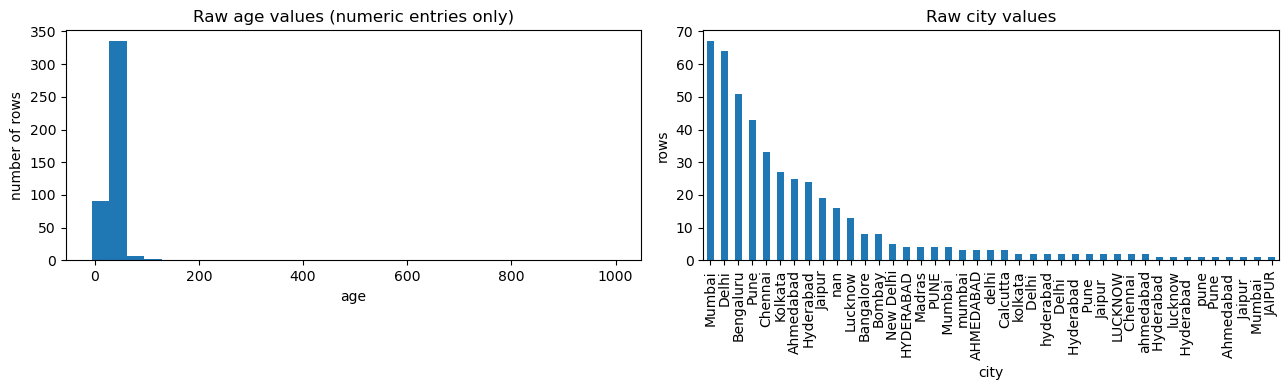

In [10]:
# ===== Exercise A9 =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot 1 - TODO (A9-1): draw a histogram of the numeric ages with 30 bins
axes[0].hist(age_check.dropna(), bins=30)
axes[0].set_title("Raw age values (numeric entries only)")
axes[0].set_xlabel("age")
axes[0].set_ylabel("number of rows")

# Plot 2 - provided: raw city labels (note the spelling / capitalisation variants)
df["city"].value_counts(dropna=False).plot(kind="bar", ax=axes[1])
axes[1].set_title("Raw city values")
axes[1].set_ylabel("rows")

plt.tight_layout()
plt.show()

**Trainer note (A9):** The histogram has one tall block at ordinary ages and isolated bars far to the right (150, 250, 999) — a picture of *invalid* values. The bar chart shows `Mumbai` split across `MUMBAI`, `mumbai`, `Bombay` and padded versions: the same city counted as several. Both are free evidence for the Issue Log.

---
# STAGE B — Clean the Dataset (60 min)
> **Why this order?** Fix the *format* first (strings, numbers), then deal with *impossible* values, *missing* categories, *duplicates*, and only then **impute** the missing numbers. Imputing before removing duplicates or impossible values would let bad rows influence the median.

## Section 6 — Working Copy and Text Standardisation

### Exercise B1 — Create a working copy

**Level 1** &nbsp;|&nbsp; **Task:** Create `clean_df`, an independent copy of `df`.

**You should see:** A message confirming the copy has the same shape as `df`.

<details><summary>💡 Hint (try first without it)</summary>

A DataFrame method named after exactly what you want to do. `clean_df = df` would NOT make a copy — it would just give the same object a second name.

</details>

In [11]:
# ===== Exercise B1 =====
# TODO (B1-1): create an independent copy of df
clean_df = df.copy()

assert clean_df is not df, "clean_df must be a COPY, not another name for df"
print("Working copy created:", clean_df.shape)

Working copy created: (460, 9)


**Trainer note (B1):** Without `.copy()`, edits to `clean_df` would also change `df` (in older pandas) or raise confusing warnings. Keeping `df` untouched lets us compare raw vs cleaned at the end.

### Exercise B2 — Correct inconsistent string formatting

**Level 2** &nbsp;|&nbsp; **Task:** (1) Remove leading/trailing spaces, (2) apply consistent capitalisation, (3) map the documented city aliases to their standard names.

**You should see:** A city list of **10 standard names + NaN** (no `MUMBAI`, no `Bombay`, no padded names).

<details><summary>💡 Hint (try first without it)</summary>

(1) a `.str` method that 'strips' whitespace. (2) a `.str` method that writes Every Word Capitalised. (3) A Series method that *replaces* values using a dictionary — careful: `map()` would turn every city NOT in the dictionary into NaN!

</details>

**🤔 Reflect (B2):** Why do we strip spaces *before* changing the capitalisation and applying the alias dictionary?

In [12]:
# ===== Exercise B2 =====
text_cols = ["customer_id", "city", "account_type", "preferred_channel"]

# (1) TODO (B2-1): remove spaces at the start and end of every text value
for col in text_cols:
    clean_df[col] = clean_df[col].str.strip()

# customer_id: IDs are always upper-case (provided)
clean_df["customer_id"] = clean_df["customer_id"].str.upper()

# (2) TODO (B2-2): consistent capitalisation, e.g. "mumbai" / "MUMBAI" -> "Mumbai"
for col in ["city", "account_type", "preferred_channel"]:
    clean_df[col] = clean_df[col].str.title()

# (3) Documented aliases - see 07_Data_Dictionary.xlsx, sheet "City Aliases"
city_aliases = {"Bombay": "Mumbai", "Bangalore": "Bengaluru", "New Delhi": "Delhi",
                "Madras": "Chennai", "Calcutta": "Kolkata"}
# TODO (B2-3): replace every alias by its standard name; all other cities must stay unchanged
clean_df["city"] = clean_df["city"].replace(city_aliases)

print(clean_df["city"].value_counts(dropna=False))

city
Mumbai       83
Delhi        76
Bengaluru    59
Pune         51
Chennai      39
Hyderabad    34
Kolkata      32
Ahmedabad    31
Jaipur       23
Lucknow      16
NaN          16
Name: count, dtype: int64


**Trainer note (B2):** Order matters: ` NEW DELHI ` → strip → `NEW DELHI` → title → `New Delhi` → alias map → `Delhi`. Mapping aliases *before* fixing case would miss `BOMBAY`. **Common bug:** `Series.map(dict)` returns NaN for keys not in the dictionary — an alternative that is safe is `.map(city_aliases).fillna(clean_df['city'])`. `str.title()` is fine here because all values are single/two-word names; for names like `McDonald` it would be wrong — mention as a limitation.

## Section 7 — Numeric Conversion and Invalid Values

### Exercise B3 — Convert numerical values stored as strings

**Level 2** &nbsp;|&nbsp; **Task:** Complete the helper `to_number()`, then use it to turn `age` and `annual_income_inr` into real numbers. Then **debug** the 'quick fix' below.

**You should see:** `age` and `annual_income_inr` become float columns. `describe()` now shows min/max (including impossible values — we deal with those next).

<details><summary>💡 Hint (try first without it)</summary>

`₹5,40,000`, `INR 540000` and `34 yrs` all become numbers once everything except digits, a decimal point and a minus sign is removed. The final step is a pandas function for converting to numbers; `errors="coerce"` turns impossible conversions into NaN.

</details>

**🤔 Reflect (B3):** Why is `errors="coerce"` safer than leaving the default (`errors="raise"`) here — and what is the danger of coercing blindly?

In [13]:
# ===== Exercise B3 =====
def to_number(series):
    """Turn text such as '₹5,40,000', 'INR 540000' or '34 yrs' into numbers (unreadable text -> NaN)."""
    only_number_chars = series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True)
    # TODO (B3-1): convert the cleaned text to numbers; anything unreadable must become NaN
    return pd.to_numeric(only_number_chars, errors="coerce")


for col in ["age", "annual_income_inr"]:
    clean_df[col] = to_number(clean_df[col])

clean_df[["age", "annual_income_inr"]].describe().round(1)

,age,annual_income_inr
count,438.0,429.0
mean,40.7,1660047.8
std,48.9,9050605.9
min,-5.0,-950000.0
25%,30.0,501000.0
50%,37.0,757500.0
75%,44.0,1160500.0
max,999.0,150000000.0


In [14]:
# ===== Exercise B3-D (Level 4: DEBUG) - FIXED =====
# BUG: the regex [^0-9] deletes EVERYTHING except digits - including the minus sign, so -450000 silently becomes +450000.
# FIX: keep the minus sign (and the decimal point): [^0-9.\-]
fixed = df["annual_income_inr"].astype(str).str.replace(r"[^0-9.\-]", "", regex=True)
fixed = pd.to_numeric(fixed, errors="coerce")

negatives_correct = (to_number(df["annual_income_inr"]) < 0).sum()
negatives_fixed = (fixed < 0).sum()
print("Negative incomes (correct conversion):", negatives_correct)
print("Negative incomes (fixed code)         :", negatives_fixed)
assert negatives_fixed == negatives_correct, "Still wrong - think about which character carries the sign!"

Negative incomes (correct conversion): 6
Negative incomes (fixed code)         : 6


**Trainer note (B3-D):** This is the most instructive bug of the day: the code runs without error but turns negative incomes into positive ones, so the invalid values *disappear from view*. Always validate a conversion against a known property (here: the count of negatives). Also note `Rs.` would be dangerous as a prefix because the `.` survives the regex — that is why the dataset uses `INR` and `₹` only.

### Exercise B4 — Detect invalid and suspicious numerical values

**Level 2** &nbsp;|&nbsp; **Task:** Create **flag columns** from the business rules, count them, and turn *impossible* values into missing values. **Suspicious values are flagged but NOT changed.**

**You should see:** A count per flag column. Afterwards no impossible value remains in the numeric columns, but suspicious values are still there and still flagged.

<details><summary>💡 Hint (try first without it)</summary>

Open `07_Data_Dictionary.xlsx` → sheet *Business Rules*. Income must be positive; the 'suspiciously high income' limit is written there in rupees.

</details>

**🤔 Reflect (B4):** What is the difference between an *invalid* and a *suspicious* value, and why do we treat them differently?

In [15]:
# ===== Exercise B4 =====
# Business rules come from 07_Data_Dictionary.xlsx -> sheet "Business Rules"
clean_df["age_invalid"] = (clean_df["age"] < 18) | (clean_df["age"] > 100)
clean_df["age_suspicious"] = clean_df["age"].between(90, 100)

# TODO (B4-1): income must be a positive number -> flag values that are zero or below
clean_df["income_invalid"] = clean_df["annual_income_inr"] <= 0
# TODO (B4-2): copy the "suspiciously high income" limit (in rupees) from the Business Rules sheet
clean_df["income_suspicious"] = clean_df["annual_income_inr"] > 10_000_000

clean_df["txn_invalid"] = clean_df["transactions_last_30d"] < 0
clean_df["txn_suspicious"] = clean_df["transactions_last_30d"] > 100
clean_df["avg_amt_invalid"] = clean_df["avg_transaction_amount_inr"] < 0
clean_df["avg_amt_suspicious"] = clean_df["avg_transaction_amount_inr"] > 200_000

flag_cols = [c for c in clean_df.columns if c.endswith("_invalid") or c.endswith("_suspicious")]
flag_counts_raw = clean_df[flag_cols].sum()          # kept for the before/after summary (C6)
print(flag_counts_raw)

age_invalid           9
age_suspicious        4
income_invalid        8
income_suspicious     5
txn_invalid           6
txn_suspicious        5
avg_amt_invalid       6
avg_amt_suspicious    5
dtype: int64


In [16]:
# Impossible values cannot be true -> treat them as MISSING. The flag column keeps the evidence.
# Suspicious values may be real -> they stay in the data and stay flagged for a human to verify.
invalid_flag_to_column = {"age_invalid": "age",
                          "income_invalid": "annual_income_inr",
                          "txn_invalid": "transactions_last_30d",
                          "avg_amt_invalid": "avg_transaction_amount_inr"}
for flag, col in invalid_flag_to_column.items():
    clean_df.loc[clean_df[flag], col] = np.nan

print("Impossible values left in the numeric columns:",
      int(clean_df["age"].lt(18).sum() + clean_df["age"].gt(100).sum()
          + clean_df["annual_income_inr"].le(0).sum()
          + clean_df["transactions_last_30d"].lt(0).sum()
          + clean_df["avg_transaction_amount_inr"].lt(0).sum()))

Impossible values left in the numeric columns: 0


**Trainer note (B4):** *Invalid* = breaks a hard rule (age 250, negative count) → cannot be true → set to missing, keep the flag, impute later. *Suspicious* = allowed by the rules but unusual (income above ₹1 crore, 480 transactions a month) → might be a VIP or an extra zero; **only the business can tell**, so we flag and keep. These flagged rows are the *unresolved exceptions* reported in C5. Note the flag counts here are on the **raw 460-row table including exact duplicate copies** because de-duplication happens later (B6).

## Section 8 — Missing and Unexpected Categorical Values

### Exercise B5 — Handle missing categorical values

**Level 2** &nbsp;|&nbsp; **Task:** (1) Replace categories that are **not** in the allowed list by `Unknown` (and flag them). (2) Fill missing categorical cells with `Unknown`.

**You should see:** `value_counts()` for each categorical column shows only the allowed values **plus** `Unknown`.

<details><summary>💡 Hint (try first without it)</summary>

A Series method called `isin` tests membership in a list. The tilde `~` means NOT.

</details>

**🤔 Reflect (B5):** When would filling a missing category with the *mode* (most frequent value) be a bad idea?

In [17]:
# ===== Exercise B5 =====
valid_values = {"account_type": ["Savings", "Current", "Premium"],
                "preferred_channel": ["Mobile", "Branch", "Web"]}

clean_df["category_unexpected"] = False
for col, allowed in valid_values.items():
    # TODO (B5-1): True where a value is present but NOT in the allowed list (hint: isin and ~)
    unexpected = clean_df[col].notna() & ~clean_df[col].isin(allowed)
    clean_df["category_unexpected"] = clean_df["category_unexpected"] | unexpected
    clean_df.loc[unexpected, col] = "Unknown"        # keep the evidence in category_unexpected

# Fill truly missing categorical cells with an explicit placeholder
for col in ["city", "account_type", "preferred_channel"]:
    # TODO (B5-2): fill the missing cells with the text "Unknown" (hint: a method that fills N/A values)
    clean_df[col] = clean_df[col].fillna("Unknown")

for col in ["city", "account_type", "preferred_channel"]:
    print(clean_df[col].value_counts(dropna=False), "\n")

city
Mumbai       83
Delhi        76
Bengaluru    59
Pune         51
Chennai      39
Hyderabad    34
Kolkata      32
Ahmedabad    31
Jaipur       23
Lucknow      16
Unknown      16
Name: count, dtype: int64 

account_type
Savings    249
Current    112
Premium     79
Unknown     20
Name: count, dtype: int64 

preferred_channel
Mobile     226
Web        142
Branch      66
Unknown     26
Name: count, dtype: int64 



**Trainer note (B5):** `Unknown` keeps the fact that the value was missing (information a model may use). Mode-filling would invent data — e.g. turning every blank into `Savings` — and *hides* missingness. For a nominal column with few missing values mode-fill can be acceptable, but it should be a conscious, documented choice. We also kept a `category_unexpected` flag so `Gold` / `ATM` cases are not silently lost.

## Section 9 — Duplicates and Conflicting Customer IDs

### Exercise B6 — Remove verified exact duplicates

**Level 1** &nbsp;|&nbsp; **Task:** Remove rows that are exact copies of an earlier row (keep the first), then verify that you removed exactly as many rows as you found in A7.

**You should see:** `Rows before` / `Rows after` / `Removed`, and no assertion error.

<details><summary>💡 Hint (try first without it)</summary>

The method name is the word 'drop' followed by the word you used in A7. Resetting the index afterwards keeps row numbers tidy.

</details>

In [18]:
# ===== Exercise B6 =====
rows_before = len(clean_df)

# TODO (B6-1): drop rows that are exact copies of an earlier row (keep the first occurrence)
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

rows_after = len(clean_df)
print("Rows before:", rows_before, "| Rows after:", rows_after, "| Removed:", rows_before - rows_after)
assert rows_before - rows_after == exact_duplicate_count, "Removed a different number of rows than the exact duplicates found in A7!"

Rows before: 460 | Rows after: 448 | Removed: 12


**Trainer note (B6):** The assertion ties B6 to A7: de-duplication removed *exactly* the rows A7 counted — no more. If a student had removed all repeated IDs the assertion would fail. Cleaning (B2–B5) never created new duplicates because exact copies stay identical after identical cleaning.

### Exercise B7 — Flag conflicting customer identifiers

**Level 2** &nbsp;|&nbsp; **Task:** Create a boolean column `id_conflict_flag` that is True for every row whose `customer_id` still appears more than once. **Do not delete these rows.**

**You should see:** A flag column, then a table of the flagged rows and a count of how many columns disagree inside each ID.

<details><summary>💡 Hint (try first without it)</summary>

A Series method named `duplicated` marks repeated values. By default it skips the *first* occurrence — look at its `keep=` argument to mark **every** row of a repeated group. Write the whole expression.

</details>

**🤔 Reflect (B7):** You now have two rows for the same customer with different incomes. Which one is correct, and how would you find out?

In [19]:
# ===== Exercise B7 =====
# TODO (B7-1): True for EVERY row whose customer_id appears more than once (write the full expression)
clean_df["id_conflict_flag"] = clean_df["customer_id"].duplicated(keep=False)

conflict_rows = clean_df[clean_df["id_conflict_flag"]].sort_values("customer_id")
print("Rows flagged:", len(conflict_rows), "| distinct IDs:", conflict_rows["customer_id"].nunique())

compare_cols = ["account_type", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]
display(conflict_rows[["customer_id"] + compare_cols].head(8))

# How many distinct values does each column have inside each conflicting ID? (2 = the rows disagree)
display(conflict_rows.groupby("customer_id")[compare_cols].nunique(dropna=False).head(8))

Rows flagged: 16 | distinct IDs: 8


,customer_id,account_type,annual_income_inr,transactions_last_30d,avg_transaction_amount_inr
43,CUST0043,Savings,1148500.0,13.0,2006.84
278,CUST0043,Savings,1435500.0,18.0,3210.94
76,CUST0074,Savings,2787000.0,14.0,5062.54
264,CUST0074,Savings,3484000.0,23.0,8100.06
111,CUST0167,Savings,3234000.0,27.0,3335.17
171,CUST0167,Savings,2310000.0,18.0,4168.96
210,CUST0205,Premium,1534000.0,20.0,1484.33
250,CUST0205,Savings,1074000.0,29.0,1929.63


,account_type,annual_income_inr,transactions_last_30d,avg_transaction_amount_inr
customer_id,,,,
CUST0043,1,2,2,2
CUST0074,1,2,2,2
CUST0167,1,2,2,2
CUST0205,2,2,2,2
CUST0252,2,2,2,2
CUST0337,1,2,2,2
CUST0347,2,2,2,2
CUST0439,2,2,2,2


**Trainer note (B7):** The IDs repeat but the *values* disagree, so these are different versions of the same customer. We cannot decide from the file alone — the answer needs a source-system lookup (e.g. last-updated timestamp, KYC record). So we **flag, keep both, and report** them as unresolved exceptions. Deleting both would lose a real customer; deleting one at random would invent a decision.

## Section 10 — Numerical Imputation

### Exercise B8 — Handle missing numerical values

**Level 1** &nbsp;|&nbsp; **Task:** Compute the **median** age and use it to fill the missing ages (you met the fill method in B5). Then **debug** the broken snippet for `transactions_last_30d`.

**You should see:** No missing values left in the four numeric columns; ages and transaction counts are whole numbers again.

<details><summary>💡 Hint (try first without it)</summary>

The statistic is the 'middle value'. Pandas computes it with a method named exactly that; missing values are ignored by default.

</details>

**🤔 Reflect (B8):** Why is median imputation sometimes preferred to mean imputation?

In [20]:
# ===== Exercise B8 =====
# TODO (B8-1): compute the median age (missing values are ignored automatically)
median_age = clean_df["age"].median()

# Fill the missing ages with that median (same method you used in B5)
clean_df["age"] = clean_df["age"].fillna(median_age)

print("Median age used for imputation:", median_age)
print("Missing ages left:", clean_df["age"].isna().sum())

Median age used for imputation: 37.0
Missing ages left: 0


In [21]:
# ===== Exercise B8-D (Level 4: DEBUG) - FIXED =====
# BUG: fillna() returns a NEW Series; the result was thrown away, so clean_df never changed.
# FIX: assign the result back to the column.
txn_median = clean_df["transactions_last_30d"].median()
clean_df["transactions_last_30d"] = clean_df["transactions_last_30d"].fillna(txn_median)

print("Missing transaction counts after the fix:", clean_df["transactions_last_30d"].isna().sum())
assert clean_df["transactions_last_30d"].isna().sum() == 0, "Still missing values - did you store the result?"

Missing transaction counts after the fix: 0


In [22]:
# Provided: same idea for the money columns. Median is used because incomes are right-skewed and
# the table still contains unverified extreme (suspicious) values that would drag a mean upward.
for col in ["annual_income_inr", "avg_transaction_amount_inr"]:
    col_median = clean_df[col].median()
    clean_df[col] = clean_df[col].fillna(col_median)
    print(f"{col}: median used = {col_median:,.2f}")

# Counts must be whole numbers again
clean_df["age"] = clean_df["age"].round().astype(int)
clean_df["transactions_last_30d"] = clean_df["transactions_last_30d"].round().astype(int)

numeric_cols = ["age", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]
print("\nMissing values left in numeric columns:\n", clean_df[numeric_cols].isna().sum())

# Mean vs median for income - why did we choose median?
display(clean_df[["annual_income_inr"]].agg(["mean", "median"]).round(0))

annual_income_inr: median used = 768,500.00
avg_transaction_amount_inr: median used = 3,422.11

Missing values left in numeric columns:
 age                           0
annual_income_inr             0
transactions_last_30d         0
avg_transaction_amount_inr    0
dtype: int64


,annual_income_inr
mean,1643424.0
median,768500.0


**Trainer note (B8):** *Median* is robust: a few extreme values (even ones we have not yet verified) barely move it, while the *mean* is pulled towards them — compare the two numbers in the last output. *Mode* suits categorical data. Imputation happens **after** removing duplicates and invalid values so those rows cannot bias the statistic. **Assumption to state in the report:** values are missing at random, so the median is a reasonable stand-in; imputing reduces variance and should be documented. In Day 02+ the median would be learned from the training set only (leakage).

## Section 11 — Dates

### Exercise B9 — Parse and validate dates

**Level 2** &nbsp;|&nbsp; **Task:** Parse `signup_date` (three known formats) into real dates, then flag dates that are missing, impossible, in the future or before the bank's launch.

**You should see:** `signup_date` becomes a datetime column. Invalid, missing and out-of-range dates become `NaT` and are flagged in `signup_date_issue`.

<details><summary>💡 Hint (try first without it)</summary>

Use the pandas function that converts text to dates. `format=` must match the pattern exactly, and `errors="coerce"` turns mismatches into NaT.

</details>

**🤔 Reflect (B9):** Why do we try the formats one by one with an explicit `format=` instead of letting pandas guess?

In [23]:
# ===== Exercise B9 =====
date_formats = ["%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y"]       # documented in the Data Dictionary
raw_dates = clean_df["signup_date"].str.strip()

parsed = pd.Series(pd.NaT, index=clean_df.index, dtype="datetime64[ns]")
for fmt in date_formats:
    # TODO (B9-1): convert the text to dates using format=fmt; non-matching text must become NaT
    attempt = pd.to_datetime(raw_dates, format=fmt, errors="coerce")
    parsed = parsed.fillna(attempt)                          # keep what is already parsed

EXTRACT_DATE = pd.Timestamp("2026-10-01")   # date the data was extracted
EARLIEST_DATE = pd.Timestamp("2015-01-01")  # before this the bank had no digital accounts

clean_df["signup_date_issue"] = parsed.isna() | (parsed < EARLIEST_DATE) | (parsed > EXTRACT_DATE)
clean_df["signup_date"] = parsed.mask(clean_df["signup_date_issue"])       # NaT where unusable
clean_df["signup_year"] = clean_df["signup_date"].dt.year.astype("Int64")

print("Dates unusable (missing / impossible / out of range):", clean_df["signup_date_issue"].sum())
print(clean_df["signup_date"].dtype)
clean_df[["customer_id", "signup_date", "signup_year", "signup_date_issue"]].head()

Dates unusable (missing / impossible / out of range): 27
datetime64[ns]


,customer_id,signup_date,signup_year,signup_date_issue
0,CUST0001,2024-08-21,2024,False
1,CUST0002,2019-06-24,2019,False
2,CUST0003,2018-08-27,2018,False
3,CUST0004,2022-12-14,2022,False
4,CUST0005,2022-02-03,2022,False


**Trainer note (B9):** Explicit formats are deterministic. Letting pandas guess a mixed column can read `04/05/2023` as April 5 or May 4 — the data dictionary states slash dates are **DD/MM/YYYY** (Indian convention), so we encode that rule. A missing date cannot be meaningfully imputed (a made-up signup date would corrupt tenure features), so these remain `NaT` and are reported as unresolved exceptions. Dates after the extract date or before the launch are impossible → NaT + flag.

---
# STAGE C — Transform and Validate (60 min)
## Section 12 — Encoding Categorical Variables

### Exercise C1 — Encode selected categorical columns

**Level 3** &nbsp;|&nbsp; **Task:** Choose the right encoding: **one-hot** for nominal columns (no natural order) and **ordinal** for ordered columns.

**You should see:** New 0/1 columns such as `city_Mumbai`, `account_type_Premium`, `preferred_channel_Web`, and an ordinal column `income_band_encoded` with values 0 / 1 / 2.

<details><summary>💡 Hint (try first without it)</summary>

City has no order (Pune is not 'greater than' Delhi). Which pandas function turns each category into its own 0/1 column?

</details>

**🤔 Reflect (C1):** Why do categorical variables need encoding for many ML algorithms? Why would ordinal-encoding `city` be misleading?

In [24]:
# ===== Exercise C1 =====
# TODO (C1-1): one-hot encode the NOMINAL columns (pandas function that creates dummy 0/1 columns)
encoded = pd.get_dummies(clean_df[["city", "account_type", "preferred_channel"]], dtype=int)
clean_df = pd.concat([clean_df, encoded], axis=1)

# Ordered column -> ordinal encoding (provided): first create an ordered income band, then map it to 0 < 1 < 2
clean_df["income_band"] = pd.cut(clean_df["annual_income_inr"], bins=[0, 500_000, 1_000_000, np.inf],
                                 labels=["Low", "Medium", "High"])
band_order = {"Low": 0, "Medium": 1, "High": 2}
clean_df["income_band_encoded"] = clean_df["income_band"].astype(str).map(band_order)

print("One-hot columns created:", list(encoded.columns))
clean_df[["city", "city_Mumbai", "account_type", "income_band", "income_band_encoded"]].head()

One-hot columns created: ['city_Ahmedabad', 'city_Bengaluru', 'city_Chennai', 'city_Delhi', 'city_Hyderabad', 'city_Jaipur', 'city_Kolkata', 'city_Lucknow', 'city_Mumbai', 'city_Pune', 'city_Unknown', 'account_type_Current', 'account_type_Premium', 'account_type_Savings', 'account_type_Unknown', 'preferred_channel_Branch', 'preferred_channel_Mobile', 'preferred_channel_Unknown', 'preferred_channel_Web']


,city,city_Mumbai,account_type,income_band,income_band_encoded
0,Mumbai,1,Savings,Medium,1
1,Mumbai,1,Current,Medium,1
2,Bengaluru,0,Unknown,Medium,1
3,Ahmedabad,0,Savings,Medium,1
4,Delhi,0,Premium,Medium,1


**Trainer note (C1):** One-hot gives each category its own independent column — no false order. Ordinal encoding is only valid when the order is real (Low < Medium < High). Cleaning *before* encoding matters: with `MUMBAI`/`Bombay` uncleaned we would have created three separate city columns for one city. Drawback: one-hot widens the table (11 city columns here); sparse/high-cardinality columns need other techniques (later sessions).

## Section 13 — Normalisation (MinMaxScaler)

### Exercise C2 — Normalise numerical columns

**Level 1** &nbsp;|&nbsp; **Task:** Rescale income into the range **0 to 1** with `MinMaxScaler` (age is scaled for you in C4).

**You should see:** An `income_normalized` column whose minimum is 0 and maximum is 1.

<details><summary>💡 Hint (try first without it)</summary>

A scaler *learns* min and max from the data and then rescales. One scikit-learn method does both steps in a single call.

</details>

**🤔 Reflect (C2):** Normalisation uses `(x - min) / (max - min)`. What happens to that formula if one extreme value is very large?

In [25]:
# ===== Exercise C2 =====
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler = MinMaxScaler()
# TODO (C2-1): learn min/max of income AND rescale it to 0-1 in one call
clean_df["income_normalized"] = scaler.fit_transform(clean_df[["annual_income_inr"]])

clean_df[["income_normalized"]].describe().loc[["min", "max", "mean"]].round(4)

,income_normalized
min,0.0000
max,1.0000
mean,0.0099


**Trainer note (C2):** `fit_transform(X)` = `fit(X)` (learn min and max) then `transform(X)` (apply). sklearn scalers need a **2-D** input, hence the double brackets `[[...]]`. Remember for Day 02+: `fit` is called on **training data only**; the test set only gets `transform` — fitting on test data would leak information (data leakage).

## Section 14 — Standardisation and Comparison

### Exercise C3 — Standardise numerical columns

**Level 3** &nbsp;|&nbsp; **Task:** Choose the scaler that produces columns with **mean 0 and standard deviation 1** (z-scores) and apply it to income.

**You should see:** An `income_standardized` column with mean ≈ 0 and standard deviation ≈ 1.

<details><summary>💡 Hint (try first without it)</summary>

One of the two scalers you imported in C2 does this. The other squeezes values into 0-1.

</details>

**🤔 Reflect (C3):** When is standardisation a better choice than normalisation?

In [26]:
# ===== Exercise C3 =====
# TODO (C3-1): choose the scaler class that gives mean 0 and standard deviation 1
std_scaler = StandardScaler()
clean_df["income_standardized"] = std_scaler.fit_transform(clean_df[["annual_income_inr"]])

clean_df[["income_standardized"]].describe().loc[["mean", "std", "min", "max"]].round(4)

,income_standardized
mean,0.0000
std,1.0011
min,-0.1673
max,16.7736


**Trainer note (C3):** `StandardScaler` computes `(x - mean) / std`. The printed pandas `std` is ≈1.001 rather than exactly 1 because pandas uses the *sample* standard deviation (ddof=1) while scikit-learn uses the *population* one (ddof=0). Standardised values are not bounded: an extreme value becomes a very large z-score (far above 3), which is itself a useful outlier signal.

### Exercise C4 — Compare scaling outputs

**Level 2** &nbsp;|&nbsp; **Task:** Compare the two scaled versions of income and explain the difference in 2–3 sentences.

**You should see:** A comparison table (min / max / mean / std) and the share of customers whose normalised income is below 0.1.

<details><summary>💡 Hint (try first without it)</summary>

No blank here. Look at where *most* customers sit on the 0–1 scale, and think about what the largest income in the data is.

</details>

**🤔 Reflect (C4):** Why are almost all normalised incomes squeezed near 0? Which unresolved data-quality exceptions cause this?

      income_normalized  income_standardized
min               0.000               -0.167
max               1.000               16.774
mean              0.010                0.000
std               0.059                1.001

99.1% of customers have a normalised income below 0.1


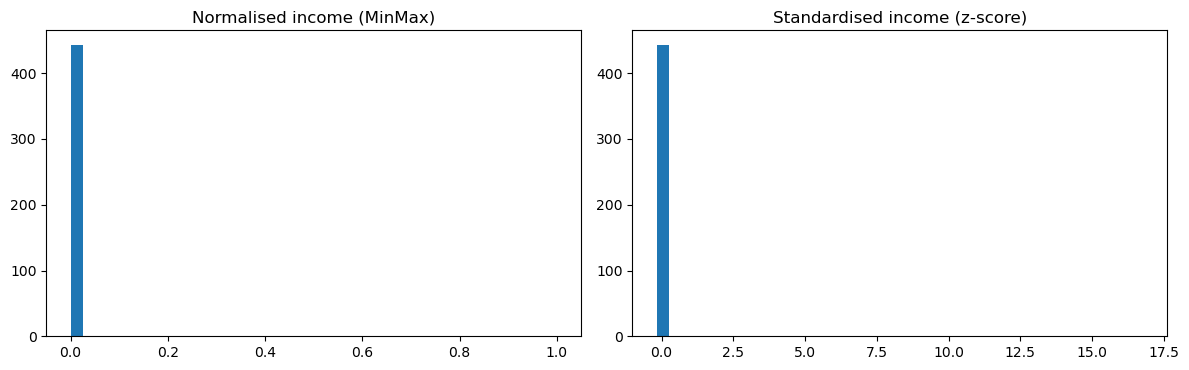

In [27]:
# ===== Exercise C4 =====
# Provided: scale AGE both ways too (each scaler object remembers its own parameters)
age_scaler = MinMaxScaler()
clean_df["age_normalized"] = age_scaler.fit_transform(clean_df[["age"]])
age_std_scaler = StandardScaler()
clean_df["age_standardized"] = age_std_scaler.fit_transform(clean_df[["age"]])

comparison = clean_df[["income_normalized", "income_standardized"]].agg(["min", "max", "mean", "std"])
print(comparison.round(3))

share_low = (clean_df["income_normalized"] < 0.1).mean() * 100
print(f"\n{share_low:.1f}% of customers have a normalised income below 0.1")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(clean_df["income_normalized"], bins=40)
axes[0].set_title("Normalised income (MinMax)")
axes[1].hist(clean_df["income_standardized"], bins=40)
axes[1].set_title("Standardised income (z-score)")
plt.tight_layout()
plt.show()

**Trainer note (C4):** The few unverified incomes above ₹1 crore stretch the MinMax range, so nearly everyone is squashed into a thin band near 0 and the 0–1 scale loses its usefulness. StandardScaler has the same problem in a different form (huge z-scores for the extreme rows, ordinary customers bunched slightly below 0). **The lesson: scaling does not fix outliers; identify and decide about them first.** This is exactly why B4 flagged them. Mini-challenge 2 repeats the scaling without them.

## Section 15 — Validation

### Exercise C5 — Validate data types and ranges

**Level 5** &nbsp;|&nbsp; **Task:** Run the provided checks, then **write three assertions yourself** (Level 5).

**You should see:** All provided assertions pass. A list of the columns that still have missing values (only `signup_date`-related ones) and the number of rows needing human review.

<details><summary>💡 Hint (try first without it)</summary>

For the three checks you write: negative values → `(col < 0).any()`; duplicates → `duplicated()`; ID pattern → `str.fullmatch(r"CUST\d{4}")`.

</details>

**🤔 Reflect (C5):** Why should we NOT force every remaining missing or suspicious value to disappear just to make the validation pass?

In [28]:
# ===== Exercise C5 (provided checks) =====
original_columns = ["customer_id", "age", "annual_income_inr", "city", "account_type",
                    "preferred_channel", "signup_date", "transactions_last_30d", "avg_transaction_amount_inr"]

# 1) required columns are present
assert set(original_columns).issubset(clean_df.columns), "A required column is missing"
# 2) row count changed ONLY because of exact duplicates
assert len(clean_df) == len(df) - exact_duplicate_count, "Unexpected row count"
# 3) numeric columns are numeric
for col in ["age", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]:
    assert pd.api.types.is_numeric_dtype(clean_df[col]), f"{col} is not numeric"
# 4) agreed age boundaries (18-100)
assert clean_df["age"].between(18, 100).all(), "Age outside 18-100"
# 5) imputed columns have no missing values
assert clean_df[["age", "annual_income_inr", "transactions_last_30d", "avg_transaction_amount_inr"]].notna().all().all()
# 6) signup_date is a real datetime column
assert pd.api.types.is_datetime64_any_dtype(clean_df["signup_date"])

print("All provided checks passed ✅")

# Unresolved missing values: which ones are left and why?
left = clean_df.isnull().sum()
print("\nColumns that still contain missing values:")
print(left[left > 0])

# Unresolved exceptions that need a human decision (provided)
clean_df["needs_review"] = (clean_df["age_suspicious"] | clean_df["income_suspicious"]
                            | clean_df["txn_suspicious"] | clean_df["avg_amt_suspicious"]
                            | clean_df["id_conflict_flag"] | clean_df["signup_date_issue"])
print("Rows needing human review:", int(clean_df["needs_review"].sum()), "of", len(clean_df))

All provided checks passed ✅

Columns that still contain missing values:
signup_date    27
signup_year    27
dtype: int64
Rows needing human review: 60 of 448


In [29]:
# ===== Exercise C5-L5 (Level 5) - SOLUTION =====
# 1) no negative counts / amounts
assert not (clean_df["transactions_last_30d"] < 0).any(), "Negative transaction count found"
assert not (clean_df["avg_transaction_amount_inr"] < 0).any(), "Negative average amount found"
# 2) no exact duplicate rows
assert not clean_df.duplicated().any(), "Exact duplicate rows remain"
# 3) every ID is CUST + 4 digits
assert clean_df["customer_id"].str.fullmatch(r"CUST\d{4}").all(), "Malformed customer_id found"
print("Student-written checks passed ✅")

Student-written checks passed ✅


**Trainer note (C5):** Validation = *prove* the data meets the rules, not *hope* it does. Note what the checks deliberately do **not** assert: that suspicious values are gone, that conflicts are resolved or that every date is present — those are *unresolved exceptions* and are reported, not hidden. `assert` stops the notebook with a message when a rule is broken.

### Exercise C6 — Before-and-after quality summary

**Level 2** &nbsp;|&nbsp; **Task:** Recalculate the missing-value and duplicate counts on `clean_df` and build the before/after summary table you will submit.

**You should see:** A table with the metrics: rows, missing cells, exact duplicates, impossible values, repeated-ID rows, and unresolved exceptions — raw vs cleaned.

<details><summary>💡 Hint (try first without it)</summary>

No blank — run the cell and read the table carefully. Be ready to explain every number.

</details>

**🤔 Reflect (C6):** Which metric improved to zero, which improved but not to zero, and why?

In [30]:
# ===== Exercise C6 =====
original_columns = ["customer_id", "age", "annual_income_inr", "city", "account_type",
                    "preferred_channel", "signup_date", "transactions_last_30d", "avg_transaction_amount_inr"]
invalid_cols = ["age_invalid", "income_invalid", "txn_invalid", "avg_amt_invalid"]
suspicious_cols = ["age_suspicious", "income_suspicious", "txn_suspicious", "avg_amt_suspicious"]

quality_summary = pd.DataFrame({
    "metric": ["Rows", "Missing cells (9 original columns)", "Exact duplicate rows",
               "Rows with a repeated customer_id", "Impossible numeric values (flagged)",
               "Suspicious numeric values (flagged)", "Unusable dates (missing/invalid/out of range)"],
    "raw": [len(df),
            int(df.isnull().sum().sum()),
            int(df.duplicated().sum()),
            int(df["customer_id"].duplicated(keep=False).sum()),
            int(flag_counts_raw[invalid_cols].sum()),
            int(flag_counts_raw[suspicious_cols].sum()),
            "n/a (text dates)"],
    "cleaned": [len(clean_df),
                int(clean_df[original_columns].isnull().sum().sum()),
                int(clean_df.duplicated().sum()),
                int(clean_df["customer_id"].duplicated(keep=False).sum()),
                int((clean_df["age"].lt(18) | clean_df["age"].gt(100)).sum()),
                int(clean_df[suspicious_cols].sum().sum()),
                int(clean_df["signup_date_issue"].sum())],
})
quality_summary

,metric,raw,cleaned
0,Rows,460,448
1,Missing cells (9 original columns),155,27
2,Exact duplicate rows,12,0
3,Rows with a repeated customer_id,40,16
4,Impossible numeric values (flagged),29,0
5,Suspicious numeric values (flagged),19,19
6,Unusable dates (missing/invalid/out of range),n/a (text dates),27


**Trainer note (C6):** Rows drop by exactly the exact duplicates; missing cells drop to the unusable dates only; repeated-ID rows fall from *(exact copies + conflicts)* to *conflicts only*; invalid values are 0 because they were converted to missing and imputed; suspicious values stay (flagged). Impossible values are counted in the raw column **before** dedup (the raw CSV), so the raw and cleaned columns are not a like-for-like row population — a good discussion point.

## Section 16 — Export

### Exercise C7 — Export the cleaned CSV

**Level 1** &nbsp;|&nbsp; **Task:** Save `clean_df` to `customer_data_cleaned.csv` **without** the row-number column, then prove the raw file is unchanged.

**You should see:** `Saved: (<rows>, <columns>)` and `Raw file untouched ✅`.

<details><summary>💡 Hint (try first without it)</summary>

A DataFrame method named `to_` + file type. `index=False` stops it writing the row numbers.

</details>

In [31]:
# ===== Exercise C7 =====
# TODO (C7-1): save clean_df to CSV (no index column)
clean_df.to_csv("customer_data_cleaned.csv", index=False)

saved = pd.read_csv("customer_data_cleaned.csv")
print("Saved:", saved.shape)
assert saved.shape == clean_df.shape, "Saved file has a different shape"

# The raw file must be exactly as we found it
assert hashlib.md5(open(DATA_FILE, "rb").read()).hexdigest() == RAW_FINGERPRINT, "Raw file was modified!"
print("Raw file untouched ✅")

Saved: (448, 47)


NameError: name 'RAW_FINGERPRINT' is not defined

**Trainer note (C7):** `index=False` avoids an unwanted `Unnamed: 0` column on reload. The exported file keeps the flag columns so downstream users can see *why* values were changed or still need review. Day 02 will start from this file.

## Section 17 — Final Reflection, Cleaning Decisions and Mini-Challenges

### Exercise C8 — Summarise your cleaning decisions

**Level 2** &nbsp;|&nbsp; **Task:** Complete the decision log: for each problem write what you did and **why**.

**You should see:** A completed table. Be specific (name the column, the method and the reason).

<details><summary>💡 Hint (try first without it)</summary>

Use the pattern: *Problem → Decision → Reason → Remaining risk*.

</details>

#### Model Cleaning Decision Log
| Problem | Decision (method) | Why | Remaining risk |
|---|---|---|---|
| Missing numeric values | Median imputation (`fillna(median)`) after impossible values → NaN and after de-duplication | Robust to extreme values; keeps all rows | Reduces variance; assumes missing-at-random |
| Missing / unexpected categories | `Unknown` placeholder + `category_unexpected` flag | Keeps the fact that it was missing; no invented value | `Unknown` becomes its own category |
| Spelling, case, spaces, city aliases | `strip` → `title` → documented alias dictionary with `replace` | Same city must have one label | Aliases not in the dictionary would stay unmerged |
| Numbers stored as text | Regex keeps `[0-9.-]`, then `to_numeric(errors='coerce')` | Handles ₹, INR, commas, `yrs`, preserves the minus sign | Coercion hides unreadable text as NaN — counts must be checked |
| Impossible numeric values | Flag, set to NaN, then impute | Cannot be true (age 250, negative counts) | Imputed values are estimates, not facts |
| Suspicious (very high) values | Flag only, keep value, list for review | May be real VIPs or typos — only the business can decide | Distorts MinMax/standard scaling until resolved |
| Exact duplicate rows | `drop_duplicates()` | Identical rows add no information and over-weight a customer | None |
| Repeated IDs with conflicting data | Flag both rows (`id_conflict_flag`), keep both | Cannot know which is right from the file alone | Customer may be double counted |
| Dates | Explicit formats → NaT + flag for missing/invalid/future/too old | Mixed formats are ambiguous; invented dates would corrupt tenure | Rows without a usable date |

### 🧠 Final reflection (write 2–4 sentences each)
1. **Problems identified:** which data-quality problems did you find, and in which columns?
2. **Cleaning decisions made:** which two decisions were the hardest, and why?
3. **Columns transformed:** which columns did you encode or scale, and with which technique?
4. **Remaining concerns:** which problems are still unresolved? Who should resolve them?
5. **What I learned today:** one thing that surprised you.

**Also answer briefly:**
- What is the difference between data *cleaning* and data *transformation*?
- Why must a scaler be fitted on training data only when we later build models?

**Model final reflection (example of a strong conclusion):**
*"The raw table had missing values in every column except `customer_id`, exact duplicate rows, repeated customer IDs with conflicting values, spelling and capitalisation variants (including Bombay/Bangalore), numbers stored as text with ₹/INR/commas, impossible ages and negative amounts, and dates in three formats plus invalid and future dates. I flagged impossible values and set them to missing, imputed numbers with the median because the data is skewed and still contains unverified extreme incomes, replaced missing/unexpected categories with 'Unknown' and kept a flag, removed only the exact duplicate rows and flagged — rather than deleted — the repeated IDs that disagree. I one-hot encoded the nominal columns and normalised/standardised income and age; I noticed that a handful of suspicious incomes squash the normalised scale, so those rows must be verified with the business. Unresolved: conflicting IDs, suspicious values and rows without a usable signup date. Cleaning repairs or flags problems in the data; transformation changes its representation (encoding, scaling) so algorithms can use it. A scaler must be fitted on training data only so no information from unseen data leaks into the model."*

**Model answers to the two short questions:** *Cleaning* fixes quality problems (errors, gaps, inconsistency); *transformation* changes representation (encoding, scaling) without fixing errors. A scaler is fitted on training data only so test-set statistics never influence preprocessing — otherwise test performance would look better than it really is (data leakage).

---
## 🏁 Independent Mini-Challenges (no blanks — you write the code)
These three challenges use the objects you created above. Work independently; ask for help only after trying.

### Mini-Challenge 1 (MC1) — Mean or median?
Using the **raw** `avg_transaction_amount_inr` (from `df`), set negative values to NaN, then compute the **mean** and **median** of the remaining values. Which one is more affected by the extreme values (> ₹2,00,000), and by how much? Which would you use to fill missing values, and why?

In [32]:
# ===== Mini-Challenge 1 - SOLUTION =====
avg_raw = pd.to_numeric(df["avg_transaction_amount_inr"], errors="coerce")
avg_valid = avg_raw.where(avg_raw >= 0)              # negatives -> NaN
avg_normal = avg_valid.where(avg_valid <= 200_000)   # also hide the suspicious values for comparison

result = pd.DataFrame({"with suspicious values": [avg_valid.mean(), avg_valid.median()],
                       "without suspicious values": [avg_normal.mean(), avg_normal.median()]},
                      index=["mean", "median"])
print(result.round(2))
print("\nMean shifts by   :", round(avg_valid.mean() - avg_normal.mean(), 2))
print("Median shifts by :", round(avg_valid.median() - avg_normal.median(), 2))

        with suspicious values  without suspicious values
mean                  13093.56                    4403.63
median                 3422.11                    3350.51

Mean shifts by   : 8689.93
Median shifts by : 71.6


**Trainer note (MC1):** The mean moves by hundreds of rupees because of five extreme rows; the median barely moves. Therefore median is the safer fill value while those rows are unverified.

### Mini-Challenge 2 (MC2) — Scale without the suspicious rows
Re-do MinMax scaling of `annual_income_inr` using **only rows where `income_suspicious` is False**. Compare the share of customers below 0.1 with the value you got in Exercise C4. What does this tell you about outliers and scaling?

In [33]:
# ===== Mini-Challenge 2 - SOLUTION =====
not_suspicious = ~clean_df["income_suspicious"]
mm = MinMaxScaler()
income_ex = mm.fit_transform(clean_df.loc[not_suspicious, ["annual_income_inr"]])

share_with = (clean_df["income_normalized"] < 0.1).mean() * 100
share_without = (income_ex < 0.1).mean() * 100
print(f"Normalised income < 0.1  -> including suspicious rows: {share_with:.1f}% | excluding them: {share_without:.1f}%")
print("Rows excluded:", int((~not_suspicious).sum()))

Normalised income < 0.1  -> including suspicious rows: 99.1% | excluding them: 21.9%
Rows excluded: 5


**Trainer note (MC2):** Without the extreme rows the 0–1 scale spreads out and far fewer customers are crushed below 0.1. Outliers must be investigated *before* scaling. (Excluding rows here is only an experiment; the real decision belongs to the business.)

### Mini-Challenge 3 (MC3) — Preview of data leakage (no model!)
Split `clean_df[["annual_income_inr"]]` into 80% *train* / 20% *test* with `train_test_split(..., test_size=0.2, random_state=42)`. Fit a `MinMaxScaler` on the **train** part only, transform the **test** part, and print the minimum and maximum of the scaled test values. Why can they fall outside 0–1, and why is that *correct* behaviour — and why must you never fit the scaler on the test set?

In [34]:
# ===== Mini-Challenge 3 - SOLUTION =====
from sklearn.model_selection import train_test_split

train, test = train_test_split(clean_df[["annual_income_inr"]], test_size=0.2, random_state=42)

leak_free = MinMaxScaler().fit(train)               # learn min/max from TRAIN only
test_scaled = leak_free.transform(test)             # apply the same rule to unseen data
print("Scaled TEST income: min = %.4f, max = %.4f" % (test_scaled.min(), test_scaled.max()))

# What a leaky pipeline would do (shown only to explain the danger): fit on test
leaky_scaled = MinMaxScaler().fit_transform(test)
print("Leaky version      : min = %.4f, max = %.4f  (always 0 and 1 -> test data influenced its own scaling)"
      % (leaky_scaled.min(), leaky_scaled.max()))

Scaled TEST income: min = -0.0003, max = 0.6662
Leaky version      : min = 0.0000, max = 1.0000  (always 0 and 1 -> test data influenced its own scaling)


**Trainer note (MC3):** Test values can fall outside 0–1 because the scaler only knows the *training* min/max — exactly what happens with genuinely new customers in production. A scaler fitted on the test set would always output 0 and 1, but it would have used information from data the model is supposed not to have seen. No model is trained in this challenge.

---
## ✅ Submission checklist
- [ ] All blanks completed, all cells run top-to-bottom without errors (*Restart & Run All*)
- [ ] `customer_data_cleaned.csv` created (Exercise C7)
- [ ] Before-and-after quality summary visible (Exercise C6)
- [ ] Issue Log (A8), Cleaning Decision Log (C8) and Final Reflection completed
- [ ] The three mini-challenges attempted

**Great work! Tomorrow we build on this cleaned dataset.** 🎓